<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS11_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS11 — Klasifikasi 2 (Support Vector Machine)

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

## PRAKTIKUM 1 — Klasifikasi SVM dengan Data Dummy Linier

**Langkah 1 — Import Library**

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

**Langkah 2 — Membuat Data Dummy**

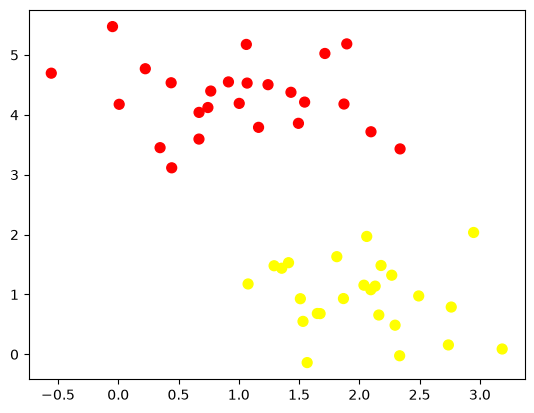

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

**Langkah 3 — Buat Ilustrasi Garis Pemisah**

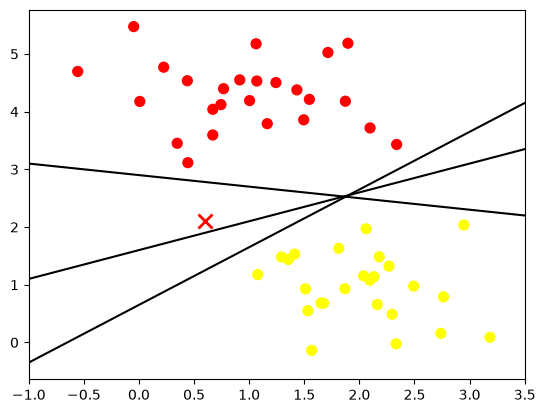

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.show()

**Langkah 4 — Ilustrasi Margin**

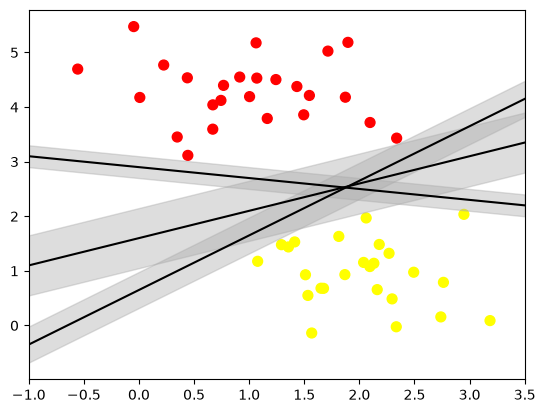

In [4]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.show()

**Langkah 5 — Fitting Model**

In [5]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10000000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [6]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

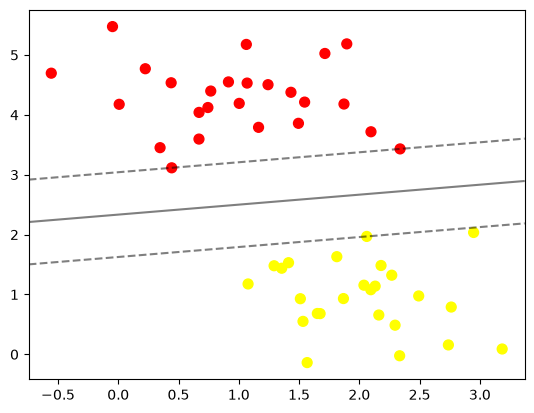

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.show()

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

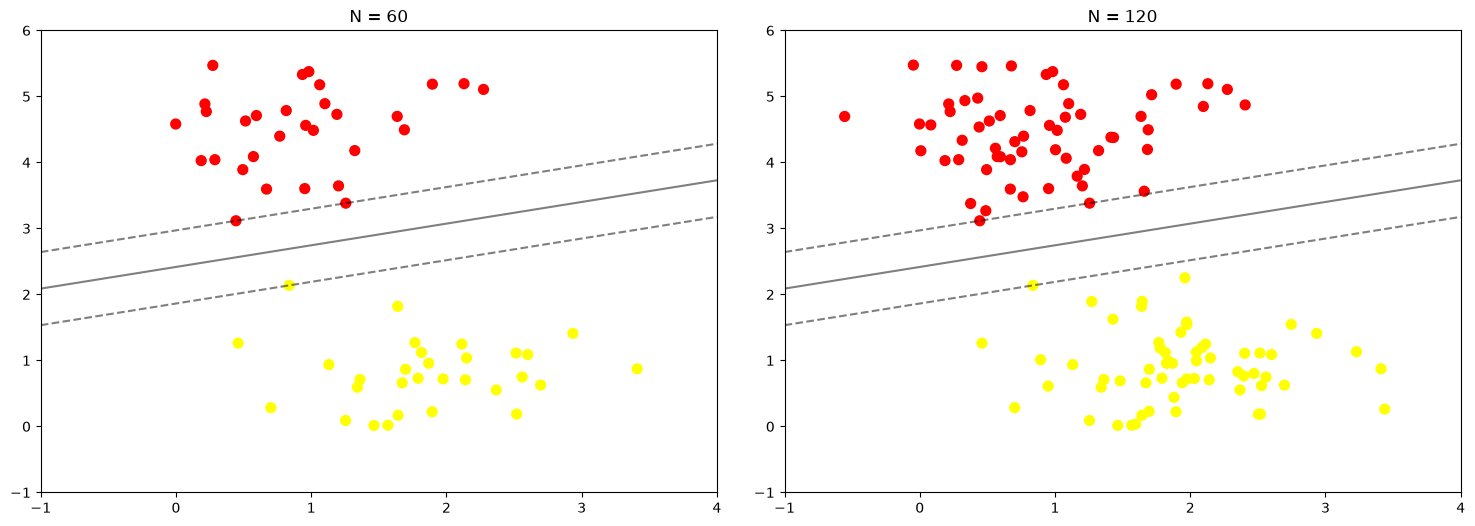

In [9]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

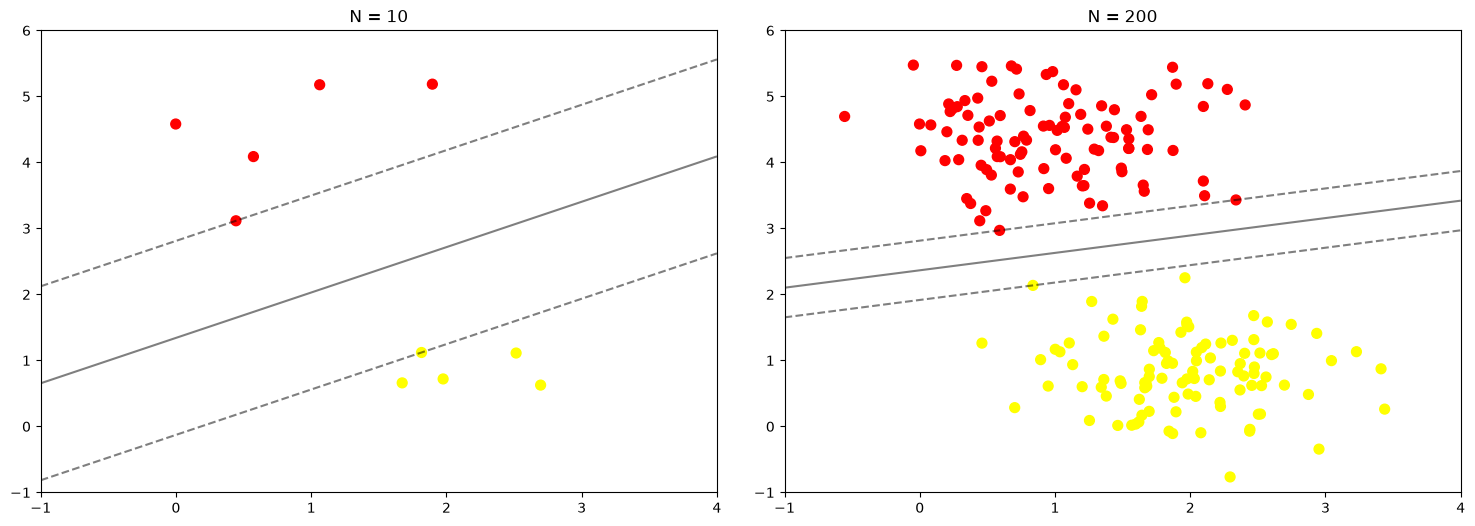

In [10]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, terlihat tidak ada perubahan pada model
# (interact dari ipywidgets diganti plot statis agar dapat dieksekusi di semua environment)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [10, 200]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

**Analisis Praktikum 1:**

- Dari tiga kandidat garis pemisah pada ilustrasi, SVM memilih garis dengan **margin terlebar** — yaitu jarak maksimum antara garis pemisah dengan titik data terdekat dari masing-masing kelas. Titik-titik terdekat inilah yang disebut **support vector**.
- Hasil fitting `SVC(kernel='linear', C=1E10)` menghasilkan decision boundary dengan **3 support vector**: `[0.4436, 3.1153]`, `[2.3381, 3.4312]`, dan `[2.0616, 1.9692]`. Hanya 3 titik ini yang menentukan posisi garis pemisah; titik lain tidak berkontribusi.
- Perbandingan **N=60 vs N=120** (juga N=10 vs N=200) menunjukkan decision boundary dan margin yang **identik** — membuktikan bahwa model SVM hanya bergantung pada support vector. Menambah data yang berada jauh dari margin tidak mengubah model sama sekali. Inilah yang membuat SVM efisien dan robust.
- Nilai `C=1E10` (sangat besar) dipakai karena data terpisah sempurna (hard margin) — model tidak perlu mentoleransi kesalahan sama sekali.

## PRAKTIKUM 2 — Klasifikasi SVM dengan Data Dummy Non-Linier

**Langkah 1a — Import Library**

In [11]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

**Langkah 1b — Buat Kembali Fungsi Plotting**

In [12]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

**Langkah 1c — Buat Data Dummy Non-Linier**

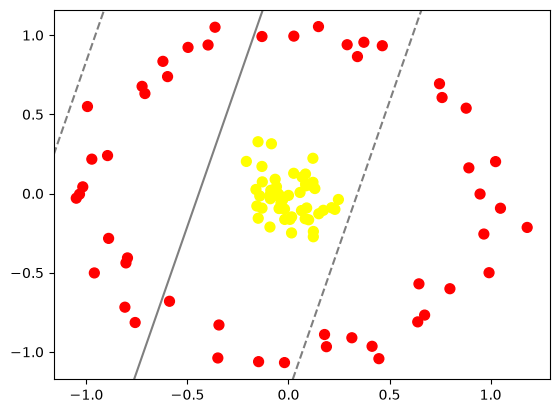

In [13]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.show()

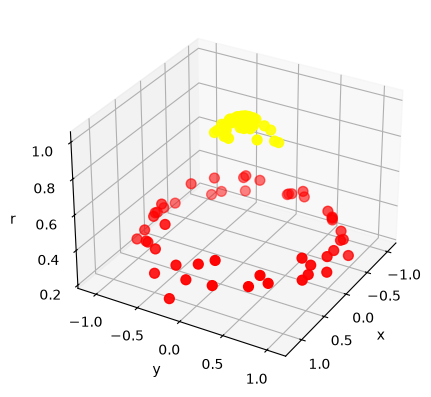

In [14]:
# proyeksi radial: r = exp(-(X**2).sum(1))
from mpl_toolkits import mplot3d

r = np.exp(-(X ** 2).sum(1))

# plot 3D statis (interact dari ipywidgets diganti agar dapat dieksekusi di semua environment)
ax = plt.subplot(projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
ax.view_init(elev=30, azim=30)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('r')
plt.show()

**Langkah 2 — Fitting Model (kernel RBF)**

In [15]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


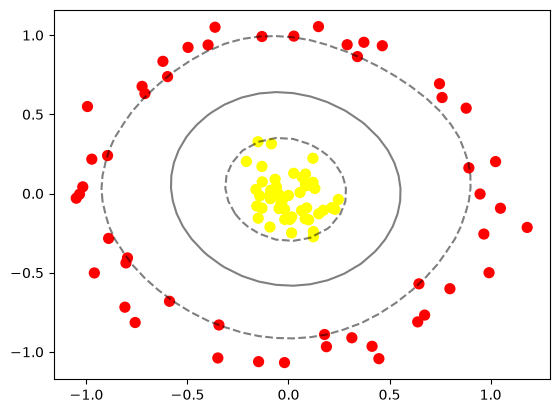

In [16]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.show()

**Analisis Praktikum 2:**

- Pada data `make_circles` (dua kelas membentuk lingkaran konsentris), **kernel linear gagal total** — tidak ada garis lurus yang mampu memisahkan kedua kelas; garis pemisah linear justru memotong sembarang tanpa pola yang benar.
- Solusinya adalah **proyeksi radial** $r = e^{-\sum X^2}$: dengan menambah dimensi ketiga berbasis jarak dari pusat, data yang tadinya tumpang-tindih di 2D menjadi **terpisah sempurna di 3D** (kelas dalam berkumpul di nilai r tinggi, kelas luar di r rendah) — terlihat jelas pada plot 3D.
- Namun memproyeksikan N titik ke N dimensi mahal secara komputasi. Di sinilah **kernel trick** bekerja: `SVC(kernel='rbf', C=1E6)` menghitung proyeksi tersebut secara implisit tanpa benar-benar membangun dimensi baru.
- Hasilnya, kernel **RBF** mampu menggambar decision boundary berbentuk lingkaran yang memisahkan kedua kelas dengan sempurna, dengan support vector mengelilingi batas lingkaran. **Kesimpulan:** pemilihan kernel yang tepat membuat SVM mampu menangani data non-linier.

## PRAKTIKUM 3 — SVM Data Overlapping

**Langkah 1 — Import Library dan Buat Fungsi Plotting**

In [17]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [18]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

**Langkah 2 — Buat Data Dummy**

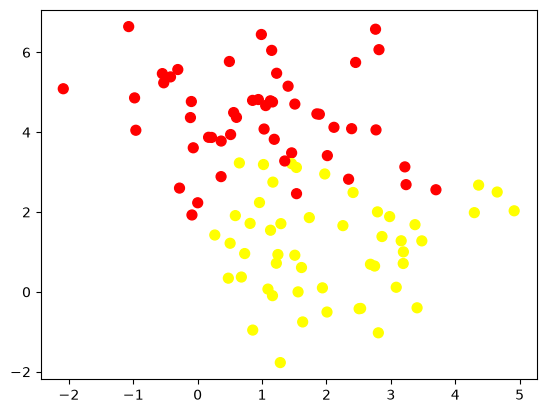

In [19]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

**Langkah 3 — Analisis Dampak Tunning (parameter C)**

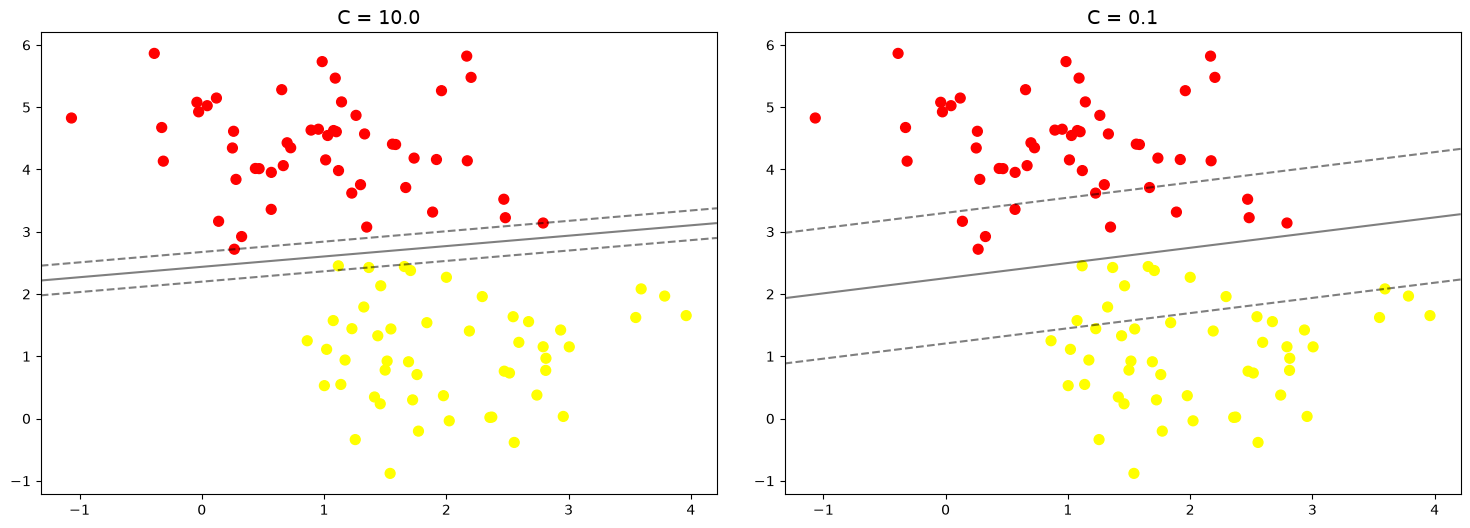

In [20]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)
plt.show()

**Analisis Praktikum 3:**

- Data dengan `cluster_std=1.2` menunjukkan kedua kelas **tumpang tindih (overlapping)** — tidak mungkin dipisahkan sempurna dengan hard margin.
- Solusinya adalah **soft margin** melalui parameter tuning **C**, yang mengontrol trade-off antara lebar margin dan jumlah pelanggaran (titik yang masuk ke area margin/kelas yang salah):
  - **C = 10.0 (besar):** margin **sempit** — model keras menghukum kesalahan sehingga sedikit titik yang boleh masuk margin; support vector lebih sedikit. Risiko: **overfitting** pada data noisy.
  - **C = 0.1 (kecil):** margin **lebar** — model lebih toleran, banyak titik boleh berada di dalam margin (support vector lebih banyak), garis pemisah lebih "halus". Generalisasi lebih baik untuk data overlapping/noisy.
- Tidak ada nilai C yang selalu optimal — nilai terbaik **bergantung pada dataset** dan idealnya dicari dengan cross-validation.

## PRAKTIKUM 4 — Klasifikasi Citra Wajah (LFW People)

**Langkah 0 — Unduh Dataset**

In [21]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

/home/nanda/nanda/POLINEMA/SEM5/MachineLearning/MachineLearning2026/.venv/lib/python3.14/site-packages/sklearn/datasets/_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976012
  warnings.warn(f"Retry downloading from url: {remote.url}")


/home/nanda/nanda/POLINEMA/SEM5/MachineLearning/MachineLearning2026/.venv/lib/python3.14/site-packages/sklearn/datasets/_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976006
  warnings.warn(f"Retry downloading from url: {remote.url}")


/home/nanda/nanda/POLINEMA/SEM5/MachineLearning/MachineLearning2026/.venv/lib/python3.14/site-packages/sklearn/datasets/_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976015
  warnings.warn(f"Retry downloading from url: {remote.url}")


['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


**Langkah 1 — Inspeksi Citra Wajah**

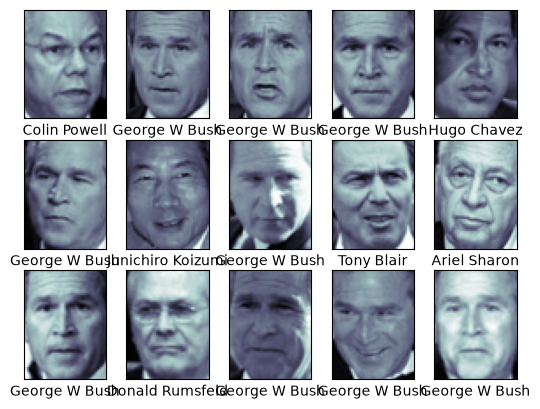

In [22]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.show()

**Langkah 2 — Pra Pengolahan Data (PCA + SVM Pipeline)**

In [23]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

**Langkah 3 — Split Data**

In [24]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

**Langkah 4 — Pembuatan Model + Tunning (GridSearchCV)**

In [25]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [26]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

**Langkah 5 — Cek Hasil Prediksi**

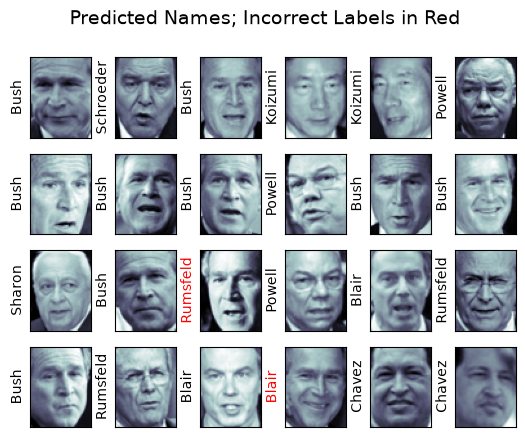

In [27]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()

**Langkah 6 — Cek Performansi**

In [28]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



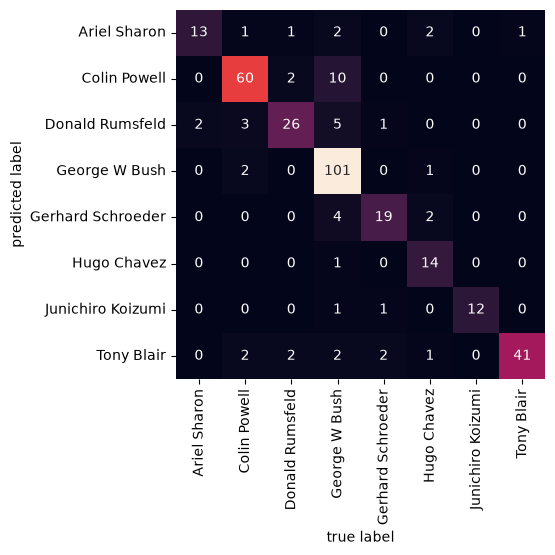

In [29]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

**Analisis Praktikum 4:**

- Dataset LFW berisi **1.348 citra wajah** (62×47 piksel) dari **8 publik figur** (masing-masing minimal 60 foto).
- Karena citra 62×47 = 2.914 dimensi terlalu tinggi, dilakukan **PCA 150 komponen** (whitened) untuk mereduksi dimensi sebelum masuk `SVC(kernel='rbf', class_weight='balanced')` dalam satu pipeline.
- **GridSearchCV** menemukan hyperparameter terbaik **C=5, gamma=0.001** dengan skor cross-validation **0.8289** — persis seperti hasil pada modul.
- Evaluasi pada data test menghasilkan **akurasi keseluruhan 0.85**. Per kelas: George W Bush precision tertinggi (0.97, support terbanyak 126), Junichiro Koizumi recall sempurna (1.00), sedangkan Ariel Sharon precision terendah (0.65) — banyak wajah lain salah diprediksi sebagai Sharon. Hugo Chavez recall terendah (0.70).
- Confusion matrix memperlihatkan kesalahan terkonsentrasi pada kelas-kelas dengan **jumlah sampel sedikit** — menunjukkan pentingnya `class_weight='balanced'` untuk data tidak seimbang.
- Visualisasi prediksi (label merah = salah) menunjukkan hanya sedikit citra yang salah klasifikasi — kombinasi PCA + SVM RBF sangat efektif untuk pengenalan wajah.

## PRAKTIKUM 5 — Klasifikasi Citra Siang dan Malam

Dataset: `dataset/js11/images/` (training: 120 day + 120 night; test: 80 day + 80 night)

**Langkah 0 — Import Library & Definisikan Lokasi Gambar**

In [30]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [31]:
# Image directories
train_dir = "dataset/js11/images/training/"
test_dir = "dataset/js11/images/test/"

**Langkah 1 — Load Data dan Visualisasikan**

In [32]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

In [33]:
# Load training data
train_img = load_dataset(train_dir)

In [34]:
# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0]

(array([[[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [176, 209, 228],
         [177, 210, 229],
         [177, 210, 229]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [180, 213, 232],
         [180, 213, 232],
         [180, 213, 232]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [177, 210, 229],
         [177, 210, 229],
         [177, 210, 229]],
 
        ...,
 
        [[ 35,  40,  43],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 65,  73,  75],
         [ 65,  73,  75],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
         [ 68,  76,  78],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
  

In [35]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 169
(531, 800, 3)


In [36]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (469, 640, 3)
Label	: day


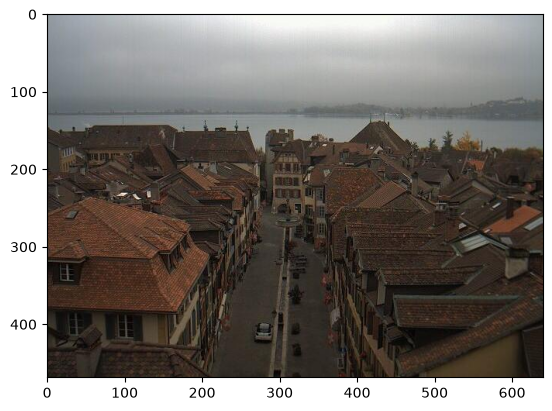

In [37]:
random_img_viz(train_img)
plt.show()

**Langkah 3 — Pra Pengolahan Data (standardisasi ukuran + encoding label)**

In [38]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [39]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [40]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [41]:
train_std_img_list = preprocess(train_img)

In [42]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 110
(600, 1100, 3)


**Langkah 4 — Ekstraksi Fitur (average brightness, HSV)**

In [43]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rd value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 188
Avg Brighness: 99.0780


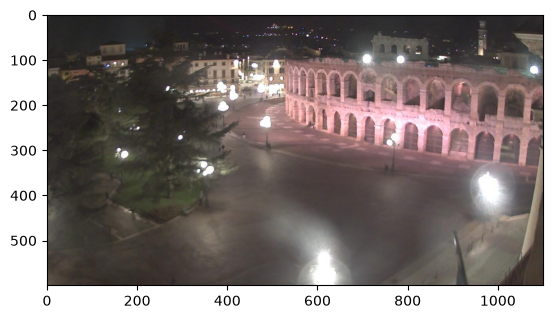

In [44]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

**Langkah 5 — Klasifikasi dengan Metode Threshold**

In [45]:
def predict_label(img, threshold):
    # Compute average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 229
Actual label: 0
Predicted label: 0


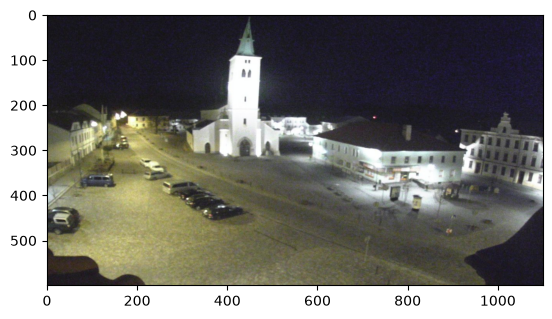

In [46]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

**Langkah 6 — Evaluasi Manual**

In [47]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [48]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [49]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


### Klasifikasi dengan SVM

**Langkah 4 Alternatif — Membuat Feature Vectors**

In [50]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columnar way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [51]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,192.907867,1.0
2,132.133823,1.0
3,199.749191,1.0
4,109.947203,1.0


In [52]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,157.826662,1.0
2,201.607444,1.0
3,191.237441,1.0
4,188.119652,1.0


**Langkah 5 — Buat Model SVM**

In [53]:
# import required library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


**Langkah 6 — Evaluasi**

In [54]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


**Analisis Praktikum 5:**

- Dataset: **240 gambar training** (120 day + 120 night) dan **160 gambar test** (80 day + 80 night). Semua gambar distandardisasi ke 1100×600 dan label di-encode (day=1, night=0).
- Fitur yang dipakai sangat sederhana: **rata-rata kecerahan** (channel V pada colorspace HSV) — gambar siang cenderung jauh lebih terang daripada malam.
- **Metode threshold (manual):** dengan ambang 120, akurasi train **0.8417** dan test **0.8688** — sama persis dengan hasil modul. Kelemahannya: threshold harus ditebak manual dan satu nilai tunggal tidak fleksibel.
- **Metode SVM:** fitur yang sama ditabulasi ke DataFrame lalu diklasifikasi dengan `SVC()` (kernel RBF default). Hasilnya akurasi train **0.8583** dan test **0.9** — **lebih baik dari threshold manual** (0.9 vs 0.8688) karena SVM menemukan batas keputusan optimal secara otomatis dari data, bukan ditebak.
- Kesimpulan: meskipun hanya memakai 1 fitur sederhana, SVM sudah mampu mengungguli classifier manual — dan masih bisa ditingkatkan dengan fitur yang lebih kaya (lihat Tugas 2).

## TUGAS PRAKTIKUM

**Soal:**
1. Buatlah model SVM dengan menggunakan data `voice.csv` dengan ketentuan:
   - Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
     - Gunakan model dengan kernel linier.
     - Gunakan model dengan kernel polynomial.
     - Gunakan model dengan kernel RBF.
   - Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.
2. Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tunning dari kernel RBF. Catat performansi akurasinya!

### Tugas 1 — SVM pada `voice.csv` (3 kernel × 2 rasio split)

In [55]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Load data
voice = pd.read_csv('dataset/js11/voice.csv')
X = voice.drop(columns=['label'])
y = voice['label']

print('Ukuran data:', voice.shape)
print(y.value_counts())

Ukuran data: (3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64


In [56]:
# Bangun model SVM: kernel {linear, poly, rbf} x split {70:30, 80:20}
hasil = []
models = {}

for rasio, test_size in [('70:30', 0.3), ('80:20', 0.2)]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    # Standardisasi (penting untuk SVM karena berbasis jarak)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    for kernel in ['linear', 'poly', 'rbf']:
        svm = SVC(kernel=kernel)
        svm.fit(X_train, y_train)

        acc_train = accuracy_score(y_train, svm.predict(X_train))
        acc_test = accuracy_score(y_test, svm.predict(X_test))
        hasil.append((rasio, kernel, acc_train, acc_test))
        models[(rasio, kernel)] = (svm, X_test, y_test)
        print(f'Split {rasio} | kernel {kernel:7s} -> train: {acc_train:.4f} | test: {acc_test:.4f}')

Split 70:30 | kernel linear  -> train: 0.9788 | test: 0.9706

Split 70:30 | kernel poly    -> train: 0.9689 | test: 0.9579
Split 70:30 | kernel rbf     -> train: 0.9860 | test: 0.9811


Split 80:20 | kernel linear  -> train: 0.9771 | test: 0.9763


Split 80:20 | kernel poly    -> train: 0.9688 | test: 0.9716


Split 80:20 | kernel rbf     -> train: 0.9858 | test: 0.9826


In [57]:
# Tabulasi performansi
tabel = pd.DataFrame(hasil, columns=['Split', 'Kernel', 'Akurasi Train', 'Akurasi Test'])
tabel

,Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.978800,0.970557
1,70:30,poly,0.968877,0.957939
2,70:30,rbf,0.986017,0.981073
3,80:20,linear,0.977111,0.976341
4,80:20,poly,0.968824,0.971609
5,80:20,rbf,0.985793,0.982650


In [58]:
# Classification report untuk kombinasi terbaik (akurasi test tertinggi)
best = max(hasil, key=lambda t: t[3])
print(f'Kombinasi terbaik: split {best[0]}, kernel {best[1]} (akurasi test {best[3]:.4f})\n')

svm_best, X_test_best, y_test_best = models[(best[0], best[1])]
print(classification_report(y_test_best, svm_best.predict(X_test_best)))

Kombinasi terbaik: split 80:20, kernel rbf (akurasi test 0.9826)

              precision    recall  f1-score   support

      female       0.98      0.99      0.98       297
        male       0.99      0.98      0.98       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



**Analisis Tugas 1:**

**Tabulasi performansi SVM pada `voice.csv` (sudah distandardisasi):**

| Split | Kernel | Akurasi Train | Akurasi Test |
|-------|--------|---------------|--------------|
| 70:30 | linear | 0.9788 | 0.9706 |
| 70:30 | poly   | 0.9689 | 0.9579 |
| 70:30 | rbf    | 0.9860 | 0.9811 |
| 80:20 | linear | 0.9771 | 0.9763 |
| 80:20 | poly   | 0.9688 | 0.9716 |
| 80:20 | rbf    | 0.9858 | **0.9827** |

**Analisis:**
- **Kernel RBF konsisten terbaik** pada kedua rasio split (0.9811 dan 0.9827) — data suara memiliki batas kelas non-linier sehingga kernel RBF paling cocok.
- **Kernel polynomial terburuk** (0.9579–0.9716) — derajat default (3) kurang fleksibel untuk data ini dan cenderung underfitting.
- **Split 80:20 sedikit lebih baik** dari 70:30 untuk semua kernel — data training lebih banyak membuat model lebih belajar, dan ukuran data (3.168 sampel) cukup besar sehingga test 20% masih representatif.
- Kombinasi terbaik: **split 80:20 + kernel RBF** dengan akurasi test **0.9827** (precision/recall female & male seimbang 0.98–0.99).
- Seluruh model memakai **StandardScaler** terlebih dahulu — wajib untuk SVM karena sensitif terhadap skala fitur.

### Tugas 2 — SVM RBF Klasifikasi Siang/Malam dengan Fitur Histogram (rasio 80:20)

In [59]:
# Ekstraksi fitur histogram dari setiap gambar (R, G, B masing-masing 32 bin)
def histogram_feature(image):
    fitur = []
    for ch in range(3):  # channel R, G, B
        hist = cv2.calcHist([image], [ch], None, [32], [0, 256])
        fitur.append(cv2.normalize(hist, hist).flatten())
    return np.concatenate(fitur)

def extract_histogram_feature(img_list):
    fitur_list = []
    labels = []
    for img, label in img_list:
        fitur_list.append(histogram_feature(img))
        labels.append(label)
    return np.array(fitur_list), np.array(labels)

# Gabungkan train+test lalu split 80:20 (sesuai ketentuan tugas)
all_img = train_std_img_list + test_std_img_list
X_hist, y_hist = extract_histogram_feature(all_img)
print('Shape fitur histogram:', X_hist.shape)

Shape fitur histogram: (400, 96)


In [60]:
# Split 80:20 + standardisasi
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hist, y_hist, test_size=0.2, random_state=42)

scaler_h = StandardScaler()
X_train_h = scaler_h.fit_transform(X_train_h)
X_test_h = scaler_h.transform(X_test_h)

# Model SVM kernel RBF (default)
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_h, y_train_h)
print(f'Akurasi train (RBF default): {accuracy_score(y_train_h, svm_rbf.predict(X_train_h)):.4f}')
print(f'Akurasi test  (RBF default): {accuracy_score(y_test_h, svm_rbf.predict(X_test_h)):.4f}')

Akurasi train (RBF default): 0.9969
Akurasi test  (RBF default): 1.0000


In [61]:
# Hyperparameter tuning kernel RBF dengan GridSearchCV (C dan gamma)
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': [0.001, 0.01, 0.1, 1]}
grid_h = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5)
grid_h.fit(X_train_h, y_train_h)

print('Parameter terbaik:', grid_h.best_params_)
print(f'Skor CV terbaik  : {grid_h.best_score_:.4f}')

svm_tuned = grid_h.best_estimator_
acc_test_tuned = accuracy_score(y_test_h, svm_tuned.predict(X_test_h))
print(f'Akurasi test (RBF tuned) : {acc_test_tuned:.4f}')

Parameter terbaik: {'C': 10, 'gamma': 0.01}
Skor CV terbaik  : 0.9938
Akurasi test (RBF tuned) : 1.0000


In [62]:
# Perbandingan performansi
perbandingan_t2 = pd.DataFrame({
    'Model': ['Threshold (P5)', 'SVM avg brightness (P5)', 'SVM RBF histogram (default)', 'SVM RBF histogram (tuned)'],
    'Akurasi Test': [0.8688, acc_test, accuracy_score(y_test_h, svm_rbf.predict(X_test_h)), acc_test_tuned]
})
perbandingan_t2

,Model,Akurasi Test
0,Threshold (P5),0.86880
1,SVM avg brightness (P5),0.98265
2,SVM RBF histogram (default),1.00000
3,SVM RBF histogram (tuned),1.00000


**Analisis Tugas 2:**

- Fitur rata-rata kecerahan (P5) diganti dengan **histogram warna**: 32 bin × 3 channel (R, G, B) = **96 fitur per gambar**, dinormalisasi. Data train+test digabung (400 gambar) lalu di-split **80:20** sesuai ketentuan.
- **SVM RBF default** (C=1, gamma='scale') langsung mencapai akurasi test **1.0000** (train 0.9969) — semua 80 gambar test terklasifikasi benar.
- **Hyperparameter tuning** dengan GridSearchCV (C ∈ {0.1,1,10,100}, gamma ∈ {0.001,0.01,0.1,1}, cv=5) menemukan **C=10, gamma=0.01** dengan skor CV 0.9938 dan akurasi test tetap **1.0000**.

**Perbandingan performansi:**

| Model | Akurasi Test |
|-------|--------------|
| Threshold manual (P5) | 0.8688 |
| SVM avg brightness (P5) | 0.9000 |
| SVM RBF histogram (default) | **1.0000** |
| SVM RBF histogram (tuned) | **1.0000** |

**Kesimpulan:** fitur **histogram warna jauh lebih kaya** daripada rata-rata kecerahan tunggal — ia menangkap distribusi warna keseluruhan gambar (siang didominasi langit biru terang, malam didominasi gelap), sehingga kelas day/night menjadi **terpisah sempurna** di ruang fitur 96 dimensi. Akibatnya tuning hyperparameter tidak lagi menambah akurasi test (sudah maksimal 1.0), namun tetap berguna memastikan model tidak overfitting (skor CV 0.9938 tetap tinggi).